In [1]:
from woody_filter import woody
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

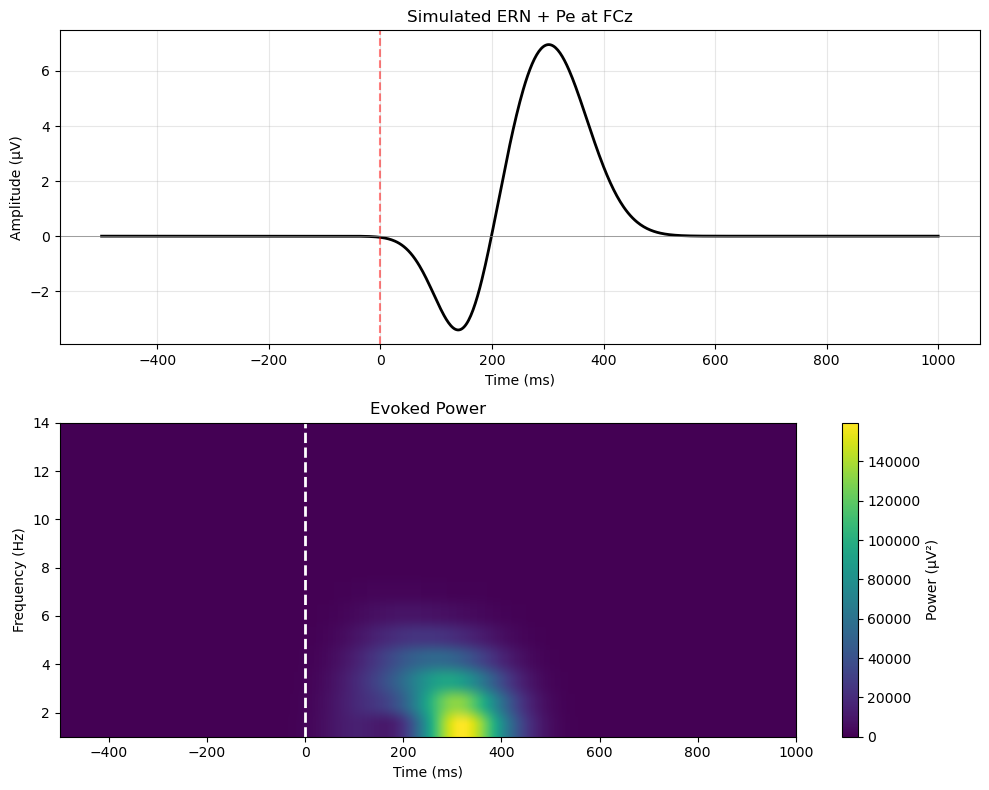

In [2]:
# ERP generation (Grand Average Waveform)
# Parameters
sfreq = 500  # Hz
tmin, tmax = -0.5, 1.0  # seconds
n_times = int((tmax - tmin) * sfreq) + 1
times = np.linspace(tmin, tmax, n_times)

# ERN parameters
ern_peak_time = 0.15  # 150ms post-error
ern_amplitude = -4  # microvolts 
ern_width = 0.05  # 50ms width

# Pe parameters
pe_peak_time = 0.3  # 300ms post-error
pe_amplitude = 7  # microvolts (positive deflection)
pe_width = 0.07  # 70ms width (broader than ERN)

# Generate ERN as Gaussian
ern = ern_amplitude * np.exp(-0.5 * ((times - ern_peak_time) / ern_width) ** 2)

# Generate Pe as Gaussian
pe = pe_amplitude * np.exp(-0.5 * ((times - pe_peak_time) / pe_width) ** 2)

# Combined ERP
erp = ern + pe

# Time-Frequency Analysis
freqs = np.arange(1, 15, 1)  # 1-15 Hz
n_cycles = freqs / 2.0

# Morlet wavelets
tfr = np.zeros((len(freqs), len(times)))
for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
    # Shorter wavelet - max 0.5 seconds
    wavelet_duration = min(3 * n_cycle / freq, 0.5)
    wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
    
    wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
    
    convolved = np.convolve(erp, wavelet, mode='same')
    tfr[idx, :] = np.abs(convolved) ** 2

# Plots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

# ERP
ax1.plot(times * 1000, erp, 'k', linewidth=2)
ax1.axvline(0, color='r', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title('Simulated ERN + Pe at FCz')
ax1.grid(alpha=0.3)

# TFR
im = ax2.imshow(tfr, aspect='auto', origin='lower', 
                extent=[times[0]*1000, times[-1]*1000, freqs[0], freqs[-1]])
ax2.axvline(0, color='white', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)')
ax2.set_ylabel('Frequency (Hz)')
ax2.set_title('Evoked Power')
plt.colorbar(im, ax=ax2, label='Power (µV²)')

plt.tight_layout()
plt.show()

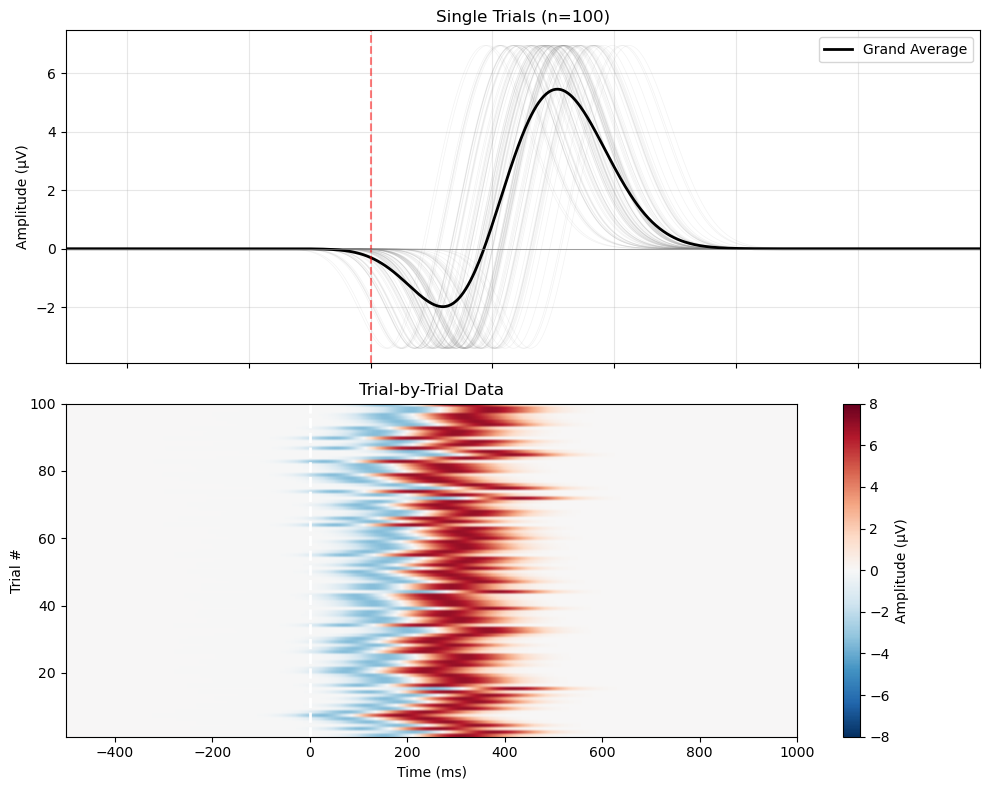

In [3]:

# Simulation parameters
n_trials = 100
jitter_sd = 0.05  # 50ms standard deviation for onset jitter

# Generate single trials and SAVE TRUE JITTERS
trials = np.zeros((n_trials, n_times))
true_jitters = np.zeros(n_trials)  # Store the true onset jitter

for trial in range(n_trials):
    onset_jitter = np.random.normal(0, jitter_sd)
    onset_jitter = np.maximum(onset_jitter, -ern_peak_time)
    true_jitters[trial] = onset_jitter  # Save it!
    
    ern = ern_amplitude * np.exp(-0.5 * ((times - (ern_peak_time + onset_jitter)) / ern_width) ** 2)
    pe = pe_amplitude * np.exp(-0.5 * ((times - (pe_peak_time + onset_jitter)) / pe_width) ** 2)
    trials[trial, :] = ern + pe
# Compute grand average
grand_avg = trials.mean(axis=0)

# Plot
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Single trials
ax1.plot(times * 1000, trials.T, 'gray', alpha=0.1, linewidth=0.5)
ax1.plot(times * 1000, grand_avg, 'k', linewidth=2, label='Grand Average')
ax1.axvline(0, color='r', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title(f'Single Trials (n={n_trials})')
ax1.legend()
ax1.grid(alpha=0.3)

# Image of all trials
im = ax2.imshow(trials, aspect='auto', origin='lower', 
                extent=[tmin * 1000, tmax * 1000, 1, n_trials],
                cmap='RdBu_r', vmin=-8, vmax=8)
ax2.axvline(0, color='white', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)')
ax2.set_ylabel('Trial #')
ax2.set_title('Trial-by-Trial Data')
plt.colorbar(im, ax=ax2, label='Amplitude (µV)')

plt.tight_layout()
plt.show()

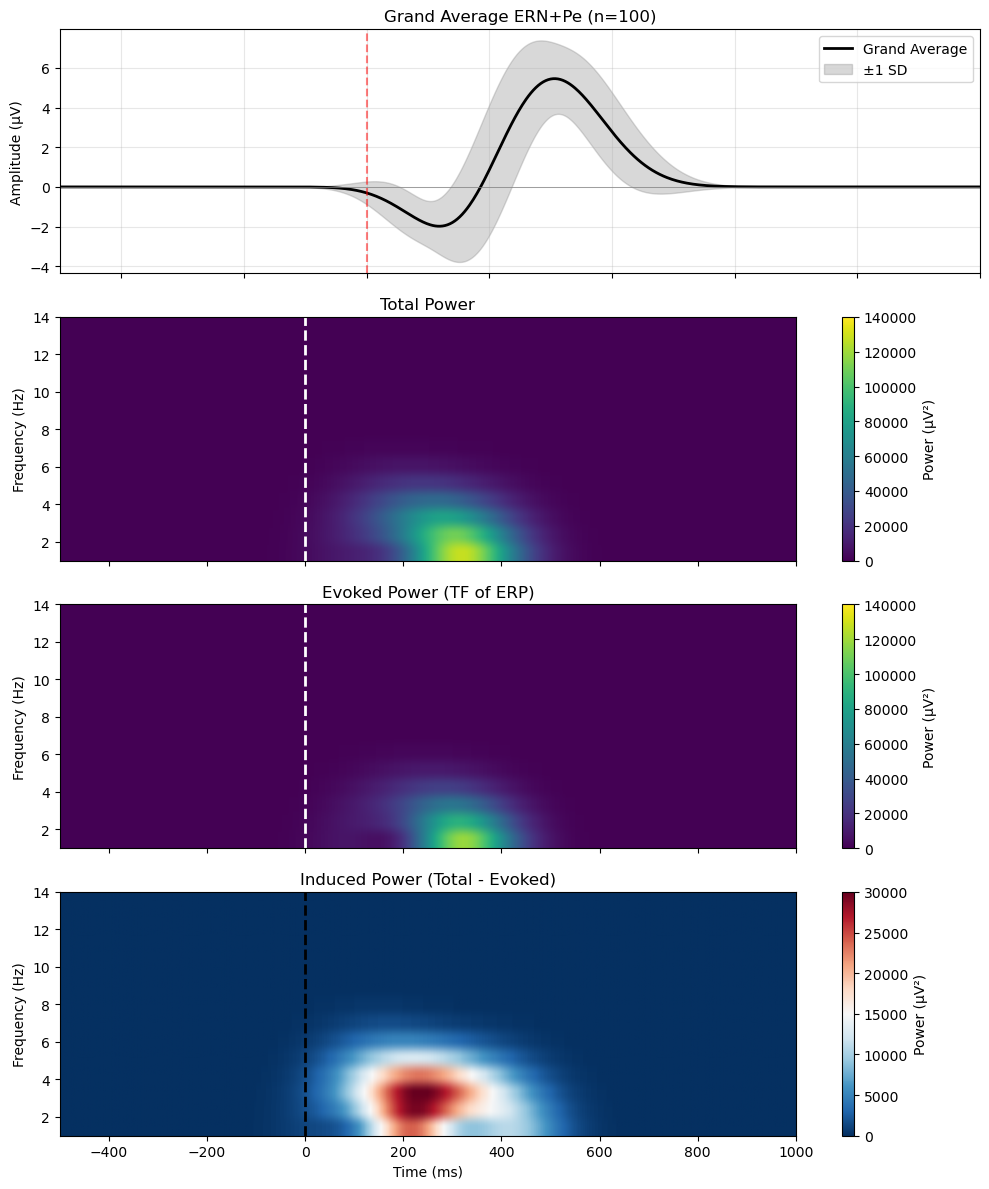

In [4]:
# Compute grand average and SD
grand_avg = trials.mean(axis=0)
sd = trials.std(axis=0)

# Time-Frequency Analysis
freqs = np.arange(1, 15, 1)  # 1-15 Hz
n_cycles = freqs / 2.0

# EVOKED POWER (TFR of averaged signal)
tfr_evoked = np.zeros((len(freqs), len(times)))
for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
    wavelet_duration = min(3 * n_cycle / freq, 0.5)
    wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
    wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
    convolved = np.convolve(grand_avg, wavelet, mode='same')
    tfr_evoked[idx, :] = np.abs(convolved) ** 2

# TOTAL POWER (average of single-trial TFRs)
tfr_total = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(trials[trial, :], wavelet, mode='same')
        tfr_total[idx, :] += np.abs(convolved) ** 2
tfr_total /= n_trials

# INDUCED POWER = Total - Evoked
tfr_induced = tfr_total - tfr_evoked

# Plot
fig, axes = plt.subplots(4, 1, figsize=(10, 12), sharex=True)

# Grand average ERP with SD
axes[0].plot(times * 1000, grand_avg, 'k', linewidth=2, label='Grand Average')
axes[0].fill_between(times * 1000, grand_avg - sd, grand_avg + sd, 
                      color='gray', alpha=0.3, label='±1 SD')
axes[0].axvline(0, color='r', linestyle='--', alpha=0.5)
axes[0].axhline(0, color='gray', linestyle='-', linewidth=0.5)
axes[0].set_ylabel('Amplitude (µV)')
axes[0].set_title(f'Grand Average ERN+Pe (n={n_trials})')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Total Power
im1 = axes[1].imshow(tfr_total, aspect='auto', origin='lower', 
                     extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=140000)
axes[1].axvline(0, color='white', linestyle='--', linewidth=2)
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_title('Total Power')
plt.colorbar(im1, ax=axes[1], label='Power (µV²)')

# Evoked Power
im2 = axes[2].imshow(tfr_evoked, aspect='auto', origin='lower', 
                     extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=140000)
axes[2].axvline(0, color='white', linestyle='--', linewidth=2)
axes[2].set_ylabel('Frequency (Hz)')
axes[2].set_title('Evoked Power (TF of ERP)')
plt.colorbar(im2, ax=axes[2], label='Power (µV²)')

# Induced Power (Total - Evoked)
im3 = axes[3].imshow(tfr_induced, aspect='auto', origin='lower', 
                     extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                     cmap='RdBu_r', vmin=0, vmax=30000)
axes[3].axvline(0, color='black', linestyle='--', linewidth=2)
axes[3].set_xlabel('Time (ms)')
axes[3].set_ylabel('Frequency (Hz)')
axes[3].set_title('Induced Power (Total - Evoked)')
plt.colorbar(im3, ax=axes[3], label='Power (µV²)')

plt.tight_layout()
plt.show()

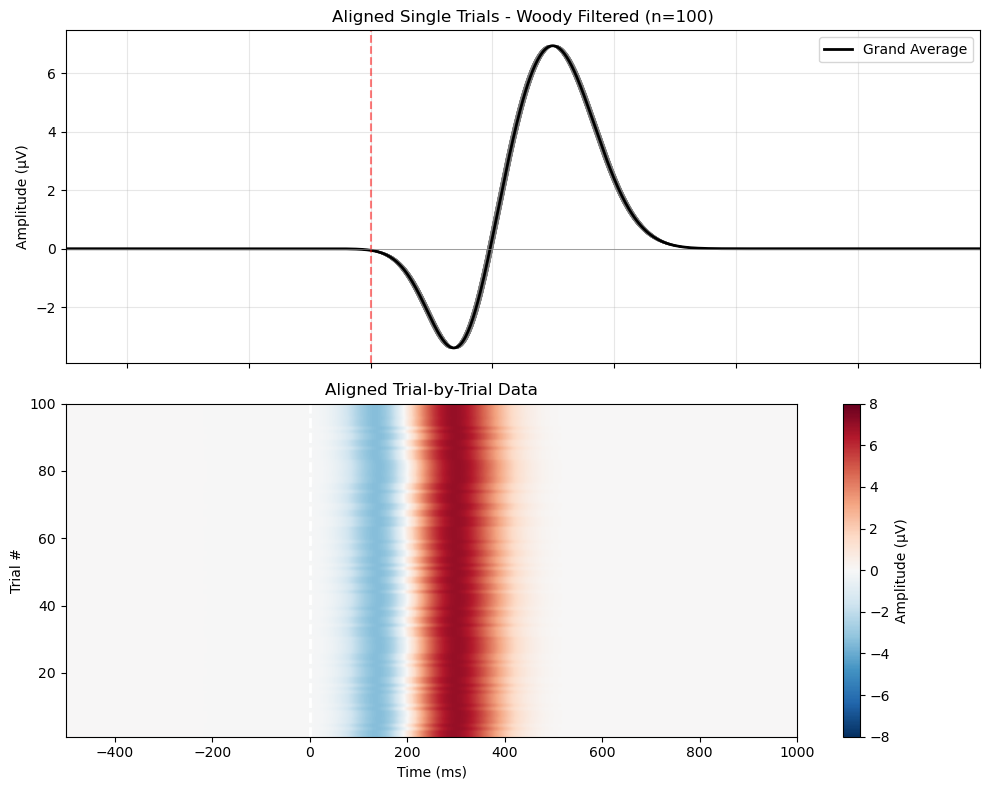

In [5]:
# Transpose to correct shape: (n_timepoints, n_trials)
trials_transposed = trials.T

# Apply iterative Woody filter
aligned_avg, detected_lags = woody(
    trials_transposed,
    tol=0.1,
    max_it=100,
    est_mthd='woody',
    xcorr_mthd='unbiased'
)

# Reconstruct individual aligned trials
aligned_trials = np.zeros_like(trials)
for i in range(n_trials):
    lag = detected_lags[i]
    if lag > 0:
        aligned_trials[i, :] = np.concatenate([trials[i, lag:], np.zeros(lag)])
    elif lag < 0:
        aligned_trials[i, :] = np.concatenate([np.zeros(-lag), trials[i, :lag]])
    else:
        aligned_trials[i, :] = trials[i, :]

grand_avg_aligned = aligned_trials.mean(axis=0)




# Plot
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Single aligned trials
ax1.plot(times * 1000, aligned_trials.T, 'gray', alpha=0.5, linewidth=0.5)
ax1.plot(times * 1000, grand_avg_aligned, 'k', linewidth=2, label='Grand Average')
ax1.axvline(0, color='r', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title(f'Aligned Single Trials - Woody Filtered (n={n_trials})')
ax1.legend()
ax1.grid(alpha=0.3)

# Image of all aligned trials
im = ax2.imshow(aligned_trials, aspect='auto', origin='lower', 
                extent=[tmin * 1000, tmax * 1000, 1, n_trials],
                cmap='RdBu_r', vmin=-8, vmax=8)
ax2.axvline(0, color='white', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)')
ax2.set_ylabel('Trial #')
ax2.set_title('Aligned Trial-by-Trial Data')
plt.colorbar(im, ax=ax2, label='Amplitude (µV)')

plt.tight_layout()
plt.show()

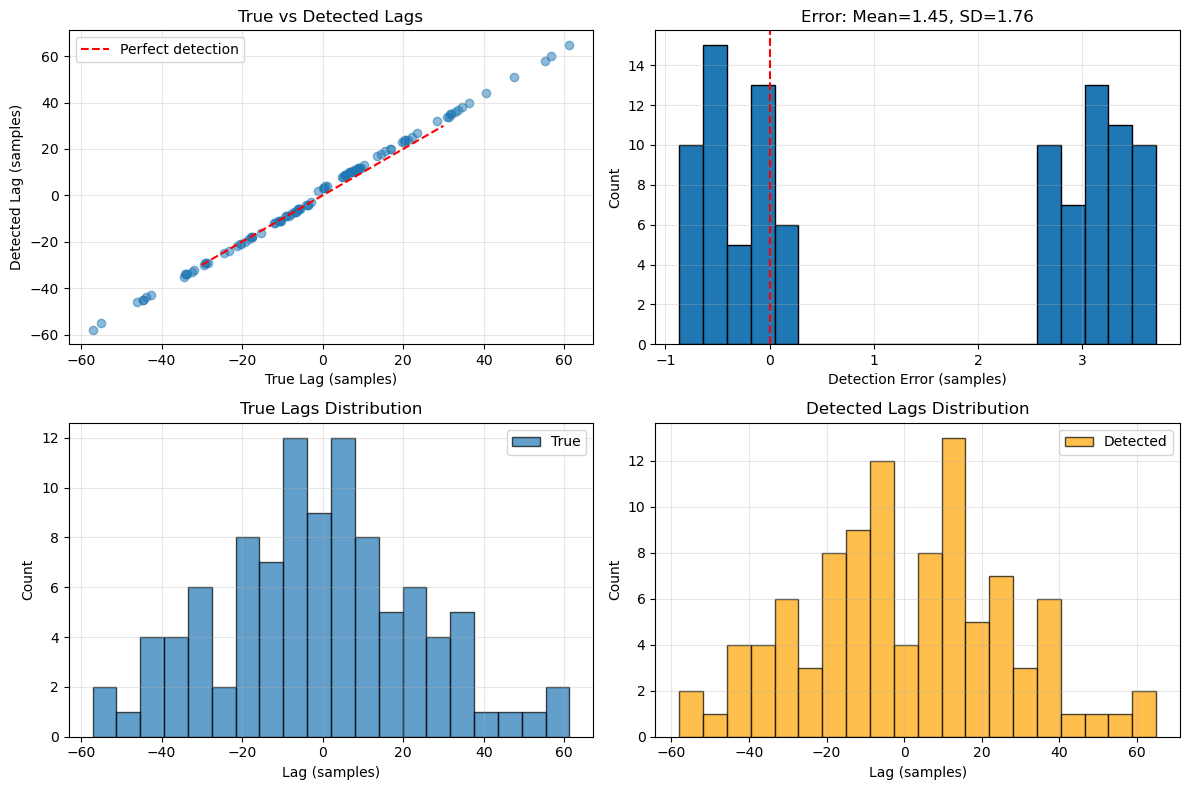

Correlation: 0.999


In [6]:
# Convert to same units
true_lags_samples = true_jitters * sfreq  # Convert seconds to samples

# Compare
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Scatter plot
axes[0, 0].scatter(true_lags_samples, detected_lags, alpha=0.5)
axes[0, 0].plot([-30, 30], [-30, 30], 'r--', label='Perfect detection')
axes[0, 0].set_xlabel('True Lag (samples)')
axes[0, 0].set_ylabel('Detected Lag (samples)')
axes[0, 0].set_title('True vs Detected Lags')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Error distribution
error = detected_lags - true_lags_samples
axes[0, 1].hist(error, bins=20, edgecolor='black')
axes[0, 1].axvline(0, color='r', linestyle='--')
axes[0, 1].set_xlabel('Detection Error (samples)')
axes[0, 1].set_ylabel('Count')
axes[0, 1].set_title(f'Error: Mean={error.mean():.2f}, SD={error.std():.2f}')
axes[0, 1].grid(alpha=0.3)

# True lags distribution
axes[1, 0].hist(true_lags_samples, bins=20, edgecolor='black', alpha=0.7, label='True')
axes[1, 0].set_xlabel('Lag (samples)')
axes[1, 0].set_ylabel('Count')
axes[1, 0].set_title('True Lags Distribution')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# Detected lags distribution
axes[1, 1].hist(detected_lags, bins=20, edgecolor='black', alpha=0.7, label='Detected', color='orange')
axes[1, 1].set_xlabel('Lag (samples)')
axes[1, 1].set_ylabel('Count')
axes[1, 1].set_title('Detected Lags Distribution')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Correlation: {np.corrcoef(true_lags_samples, detected_lags)[0,1]:.3f}")


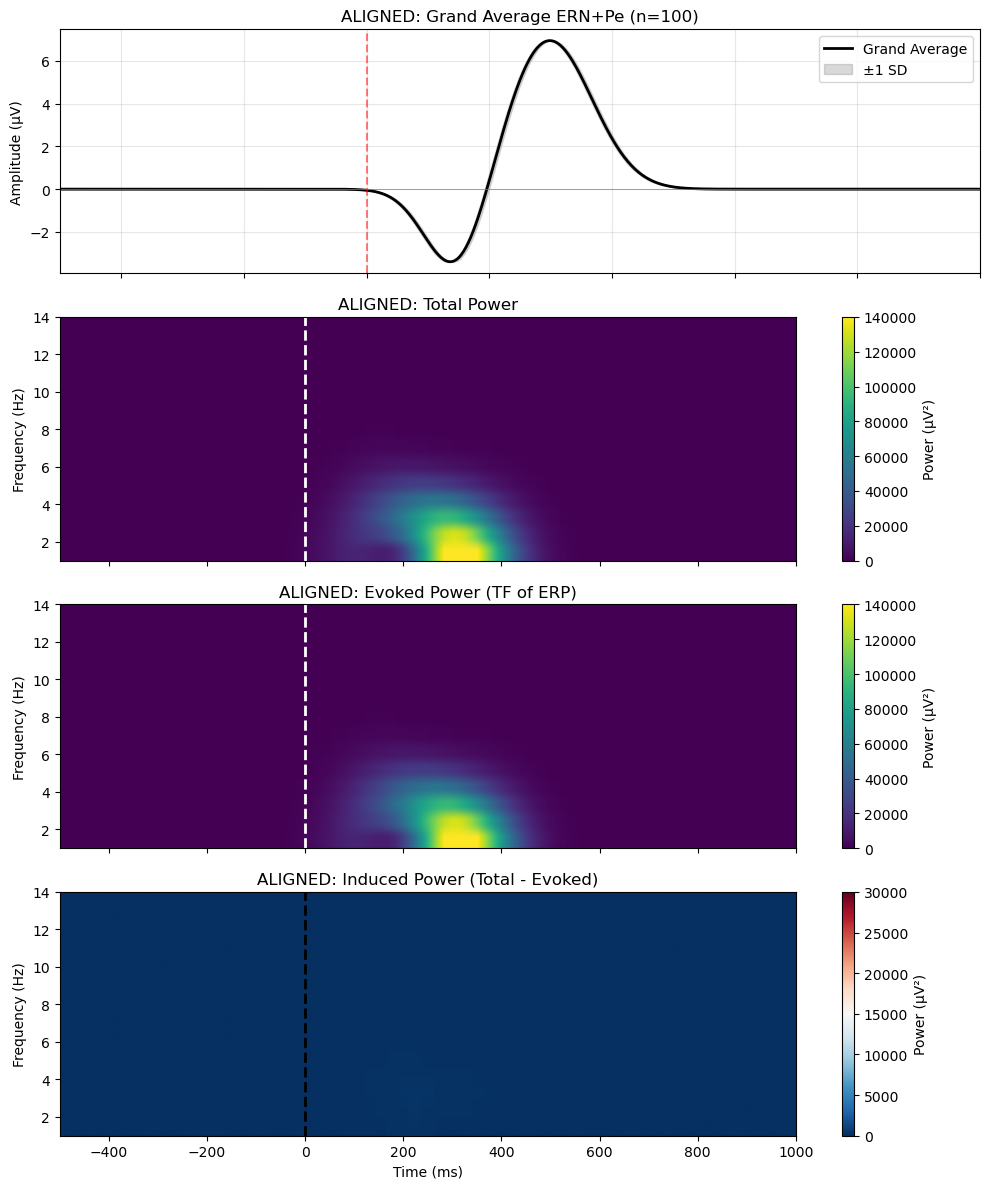

In [7]:
# Compute grand average and SD for ALIGNED trials
grand_avg_aligned = aligned_trials.mean(axis=0)
sd_aligned = aligned_trials.std(axis=0)

# Time-Frequency Analysis on ALIGNED data
freqs = np.arange(1, 15, 1)  # 1-15 Hz
n_cycles = freqs / 2.0

# EVOKED POWER ALIGNED (TFR of averaged signal)
tfr_evoked_aligned = np.zeros((len(freqs), len(times)))
for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
    wavelet_duration = min(3 * n_cycle / freq, 0.5)
    wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
    wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
    convolved = np.convolve(grand_avg_aligned, wavelet, mode='same')
    tfr_evoked_aligned[idx, :] = np.abs(convolved) ** 2

# TOTAL POWER ALIGNED (average of single-trial TFRs)
tfr_total_aligned = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(aligned_trials[trial, :], wavelet, mode='same')
        tfr_total_aligned[idx, :] += np.abs(convolved) ** 2
tfr_total_aligned /= n_trials

# INDUCED POWER ALIGNED = Total - Evoked
tfr_induced_aligned = tfr_total_aligned - tfr_evoked_aligned

# Plot
fig, axes = plt.subplots(4, 1, figsize=(10, 12), sharex=True)

# Grand average ERP with SD (ALIGNED)
axes[0].plot(times * 1000, grand_avg_aligned, 'k', linewidth=2, label='Grand Average')
axes[0].fill_between(times * 1000, grand_avg_aligned - sd_aligned, grand_avg_aligned + sd_aligned, 
                      color='gray', alpha=0.3, label='±1 SD')
axes[0].axvline(0, color='r', linestyle='--', alpha=0.5)
axes[0].axhline(0, color='gray', linestyle='-', linewidth=0.5)
axes[0].set_ylabel('Amplitude (µV)')
axes[0].set_title(f'ALIGNED: Grand Average ERN+Pe (n={n_trials})')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Total Power (ALIGNED)
im1 = axes[1].imshow(tfr_total_aligned, aspect='auto', origin='lower', 
                     extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=140000)
axes[1].axvline(0, color='white', linestyle='--', linewidth=2)
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_title('ALIGNED: Total Power')
plt.colorbar(im1, ax=axes[1], label='Power (µV²)')

# Evoked Power (ALIGNED)
im2 = axes[2].imshow(tfr_evoked_aligned, aspect='auto', origin='lower', 
                     extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=140000)
axes[2].axvline(0, color='white', linestyle='--', linewidth=2)
axes[2].set_ylabel('Frequency (Hz)')
axes[2].set_title('ALIGNED: Evoked Power (TF of ERP)')
plt.colorbar(im2, ax=axes[2], label='Power (µV²)')

# Induced Power (ALIGNED)
im3 = axes[3].imshow(tfr_induced_aligned, aspect='auto', origin='lower', 
                     extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                     cmap='RdBu_r', vmin=0, vmax=30000)
axes[3].axvline(0, color='black', linestyle='--', linewidth=2)
axes[3].set_xlabel('Time (ms)')
axes[3].set_ylabel('Frequency (Hz)')
axes[3].set_title('ALIGNED: Induced Power (Total - Evoked)')
plt.colorbar(im3, ax=axes[3], label='Power (µV²)')

plt.tight_layout()
plt.show()